# The Flowsheet Debugger

A recycle that will not close usually fails somewhere specific: a unit returns a NaN on the
first pass, one tear field oscillates while the others settle, a reactor's own solve gives up.
`fs.solve()` and `difflow.diagnostics` tell you *that* a solve failed. The debugger lets you
**watch** it: it pauses a sequential-modular solve unit by unit and tear iteration by tear
iteration, shows every stream on the way, and stops on breakpoints --- before a unit, at an
iteration, on a condition on the residual, or where the first NaN appears.

This notebook covers:

1. **Stepping** through a recycle solve and reading streams, units and the tear residual
2. **Breakpoints** on a unit, a condition and an event
3. **Post mortem**: finding the unit where a NaN is born
4. **`set tear`**: giving the next pass a different guess
5. **Record and replay**: a solve kept frame by frame, and a *what-if* that finds a second steady state
6. **Driving it from a program**: `DebugRunner` and the JSON protocol

At a terminal you would type the commands yourself at a `difflow-dbg>` prompt:

```bash
difflow debug plant.py
```

or, from a script or a notebook, `with debug.attach(): fs.solve()`. A notebook that runs
unattended cannot type, so each session below hands the same debugger its commands as a script.
The commands and their output are exactly what you would see at the prompt.

## Setup

In [1]:
import io
import sys
import warnings

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update("jax_enable_x64", True)

from difflow import (CSTR, CSTRParams, Flowsheet, IdealThermo, Mixer, Splitter, Unit,
                     make_stream, mass_action_kinetics)
from difflow import debug
from difflow.database import get_species_data
from difflow.debug import DebugQuit, DebugSession
from difflow.debug.record import compare, state_at, summarize
from difflow.debug.repl import ReplFrontend

The test case is a small isomerization loop: n-hexane is converted to 2-methylpentane in a CSTR,
and 80 % of the reactor effluent is recycled to the mixer. The splitter outlet `recycle` is the
tear stream.

In [2]:
species = ["n_hexane", "2_methylpentane"]
thermo = IdealThermo({s: get_species_data(s) for s in species})
kin = mass_action_kinetics(
    [{"reactants": {species[0]: 1.0}, "products": {species[1]: 1.0},
      "rate_params": {"A": 0.05}}], species_order=species)


def isomerization_loop():
    reactor = CSTR(CSTRParams(V=1.0, molar_density=10.0, **kin.params_kwargs()), thermo)
    fs = Flowsheet(species_order=species)
    fs.add_feed("fresh", make_stream({species[0]: 1.0, species[1]: 0.0}, T=340.0, P=101325.0))
    fs.add_unit(Unit("mixer", Mixer(species, thermo), ["fresh", "recycle"], ["reactor_feed"]))
    fs.add_unit(Unit("reactor", reactor, ["reactor_feed"], ["effluent"], params={"T_spec": 340.0}))
    fs.add_unit(Unit("split", Splitter(species), ["effluent"], ["recycle", "product"],
                     params={"split_frac": 0.8}))
    fs.add_recycle("recycle", "recycle")        # tear the splitter outlet
    return fs


fs = isomerization_loop()
plain = fs.solve(acceleration="wegstein")
print("converged:", fs.last_solve_converged, "in", fs.last_solve_iterations, "iterations")
print("product 2-methylpentane:", float(plain["product"]["F_2_methylpentane"]), "mol/s")

converged: True in 6 iterations
product 2-methylpentane: 0.3333333333193864 mol/s


A small helper runs one debugging session with a list of commands, printing to the notebook.
When the commands run out, the session detaches and the solve finishes on its own, which is
what pressing Ctrl-D at the prompt does.

In [3]:
def session(commands, **attach):
    # A debugger that reads `commands` instead of a keyboard and prints here.
    frontend = ReplFrontend(script=commands, stdin=io.StringIO(""), stdout=sys.stdout)
    return DebugSession(frontend, **attach)

## 1. Stepping through a solve

The first pause is before anything runs (`solve_start`). From there:

- `next` runs to the next unit; `step` runs to the next tear iteration;
- `where` shows the calculation order, with `->` at the current unit and `*` on tear streams;
- `p STREAM`, `p UNIT` and `p STREAM.FIELD` print what is known at this point;
- `p tear` breaks the tear residual down by stream and field, largest first;
- `p history` lists the residual so far, with a reading of it: mid-solve, how fast it is
  falling (or creeping, rising, oscillating); at the end, the verdict on the solve.

In [4]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    with debug.attach(session([
        "where",
        "next", "next",
        "p reactor_feed",
        "p reactor",
        "step",
        "p tear",
        "step", "step",
        "p history",
    ])):
        isomerization_loop().solve(acceleration="wegstein")

── difflow-dbg ── @solve_start  phase=start
   ↳ start
difflow-dbg> where
solve_start  phase=start  iteration=-
   mixer: (fresh, recycle*) -> (reactor_feed)
   reactor: (reactor_feed) -> (effluent)
   split: (effluent) -> (recycle, product)
   (* = tear stream)
difflow-dbg> next
stepping to the next unit
── difflow-dbg ── @after_unit  mixer  phase=init
   ↳ step
difflow-dbg> next
stepping to the next unit
── difflow-dbg ── @after_unit  reactor  phase=init
   ↳ step
difflow-dbg> p reactor_feed
reactor_feed:
  F_n_hexane   1.01
  F_2_methylpentane 0.01
  T            340
  P            101325
difflow-dbg> p reactor
unit reactor (CSTR)
  inlets   reactor_feed
  outlets  effluent
  V              1
  T_damping      0.3
  molar_density  10
  outlet_volumetric_basis 0
  T_spec         340
  info:
    Q            -4.11153
    molar_density 10
    balance_residual 2.17691e-16
    converged    1
    H_mix        0
difflow-dbg> step
stepping to the next iteration
── difflow-dbg ── @iteration  

The first two `next`s land in the **init** phase: before the iteration starts, difflow runs every
unit once from the feeds to guess the tear. That pass is where a bad starting point is usually
born, so the debugger stops there too. Each pause names its phase: `init`, `solve` (the
iteration), `probe` (the error probe after convergence) and `final`.

At the first `iteration` pause, `p tear` shows that the residual is entirely the recycle's flows:
`x` is the guess the pass ran on, `g(x)` what the loop sent back.

## 2. Breakpoints

| Command | Stops |
|---|---|
| `break split` (or `break unit split`) | before unit `split`, on every pass |
| `break 4`, `tbreak 4` | at tear iteration 4 (once, for `tbreak`) |
| `break if residual<1e-4 && iter>2` | at the first iteration where the condition holds |
| `break on EVENT` | `nonfinite`, `residual_rise`, `inner_unconverged`, `unit_error` |
| `watch TARGET` | (not a stop) print a target at every pause |

`continue` runs to the next breakpoint, a unit error, or the end.

In [5]:
with debug.attach(session([
    "break if residual<1e-6 && iter>1",
    "break on residual_rise",
    "watch recycle.F_n_hexane",
    "continue",
    "info",
    "break clear",
    "break split",
    "continue",
    "p effluent",
    "break clear",
    "continue",
])):
    isomerization_loop().solve(acceleration="wegstein")

── difflow-dbg ── @solve_start  phase=start
   ↳ start
difflow-dbg> break if residual<1e-6 && iter>1
conditional breakpoint: residual<1e-6 && iter>1
difflow-dbg> break on residual_rise
breakpoint on residual_rise (the tear residual went up from one iteration to the next)
difflow-dbg> watch recycle.F_n_hexane
watching recycle.F_n_hexane
difflow-dbg> continue
continuing
── difflow-dbg ── @iteration  iter 4  phase=solve  residual=2.239e-07
   ↳ condition: residual<1e-6 && iter>1
   [recycle.F_n_hexane] recycle.F_n_hexane = 2.66667
difflow-dbg> info
checkpoint   iteration
phase        solve
iteration    4
residual     2.23924e-07
method       wegstein
reason       condition: residual<1e-6 && iter>1
log_residual -6.6499
ratio        0.000945793
tears        recycle
units        3
difflow-dbg> break clear
all breakpoints cleared
difflow-dbg> break split
breakpoint before unit split
difflow-dbg> continue
continuing
── difflow-dbg ── @before_unit  split  iter 5  phase=solve
   ↳ unit split
   

The condition stopped the solve at iteration 4. `break split` then stopped before the splitter on
the next pass (iteration 5), and the watch printed the recycle flow at every stop. The final
`continue` runs to `terminated`, where the debugger always stops once to show the verdict.

## 3. Post mortem: where is the NaN born?

A NaN in one unit spreads to every unit downstream of it and then to the tear, so by the time the
solve reports a NaN residual, every stream is NaN and the cause is invisible.
`attach(on_error=True)` (`difflow debug plant.py --on-error` at a terminal) runs the solve freely
and stops **once**, at the first of:

- a unit that raises;
- a unit that turns *finite* inlets into a NaN or inf outlet (where the NaN is born, not
  every unit it passes through);
- a solve that ends unconverged.

Here a heater has a planted bug: a correlation that takes the log of `T - 400`, which is fine
above 400 K and NaN below.

In [6]:
def heater_with_a_bad_correlation(stream):
    T_out = stream["T"] + 10.0 * jnp.log(stream["T"] - 400.0)     # NaN when T < 400 K
    return make_stream({s: stream[f"F_{s}"] for s in species}, T_out, stream["P"])


def faulty_loop():
    fs = isomerization_loop()
    fs.units.insert(1, Unit("preheat", heater_with_a_bad_correlation, ["reactor_feed"], ["hot_feed"]))
    fs.units[2].inlet_names = ["hot_feed"]          # the reactor now takes the preheated feed
    return fs


faulty = faulty_loop()
faulty.solve(acceleration="wegstein", on_nonconvergence="ignore")
print("converged:", faulty.last_solve_converged, "| residual:", faulty.last_solve_residual)

converged: True | residual: 2.8741897750705903e-11


The solve says only that the residual is NaN. Post mortem, the debugger says where:

In [7]:
try:
    with debug.attach(session(["info", "p reactor_feed", "p hot_feed", "diagnose", "quit"],
                              on_error=True)):
        faulty_loop().solve(acceleration="wegstein", on_nonconvergence="ignore")
except DebugQuit:
    print("(stopped from the debugger)")

── difflow-dbg ── @after_unit  preheat  phase=init
   ↳ on-error: nonfinite
difflow-dbg> info
checkpoint   after_unit
phase        init
unit         preheat
trigger      nonfinite
reason       on-error: nonfinite
tears        -
units        4
difflow-dbg> p reactor_feed
reactor_feed:
  F_n_hexane   1.01
  F_2_methylpentane 0.01
  T            340
  P            101325
difflow-dbg> p hot_feed
hot_feed:
  F_n_hexane   1.01
  F_2_methylpentane 0.01
  T            nan
  P            101325
difflow-dbg> diagnose
residual history reads as: no tear iteration yet
non-finite streams: hot_feed
difflow-dbg> quit
stopping the solve
(stopped from the debugger)


It stopped at `preheat`, during the **init** pass, with finite inlets (340 K) and a NaN outlet:
the unit, the phase and the inlet that triggered it, before any of it reached the tear. `quit`
raises `DebugQuit` rather than returning a partial answer.

## 4. `set tear`: choosing the next guess

The debugger changes only one thing: the tear guess the next pass runs on. At an `iteration`
pause, `set tear STREAM.FIELD VALUE` replaces that iteration's step; at an `after_accel` pause it
edits the accelerated guess. The accelerator keeps its history, because every pair in it is still
a real evaluation of the loop.

An edit changes the *route* to the fixed point, not the fixed point. A solve that converges
after one converges to the same answer, but it is no longer the plain solve, so the edit is
recorded on the flowsheet in `last_solve_debug_edits`.

In [8]:
edited = isomerization_loop()
with debug.attach(session([
    "stop-at iteration",
    "continue",
    "p tear",
    "set tear recycle.F_n_hexane 3.0",
    "stop-at clear",
    "continue",
])):
    streams = edited.solve(acceleration="wegstein")

print()
print("edits recorded:", edited.last_solve_debug_edits)
print("same product as the plain solve:",
      bool(jnp.isclose(streams["product"]["F_2_methylpentane"], plain["product"]["F_2_methylpentane"])))

── difflow-dbg ── @solve_start  phase=start
   ↳ start
difflow-dbg> stop-at iteration
will stop at every iteration
difflow-dbg> continue
continuing
── difflow-dbg ── @iteration  iter 0  phase=solve  residual=4.252e-01
   ↳ stop-at iteration
difflow-dbg> p tear
stream        field                  x          g(x)       |g-x|
recycle       F_n_hexane      0.542211      0.967411      0.4252
recycle       F_2_methylpentane      0.273789      0.485389      0.2116
recycle       T                    340           340           0
recycle       P                 101325        101325           0
difflow-dbg> set tear recycle.F_n_hexane 3.0
next pass: recycle.F_n_hexane = 3 (was 0.967411)
difflow-dbg> stop-at clear
stop-at back to the defaults: terminated, unit_error
difflow-dbg> continue
continuing
── difflow-dbg ── @terminated  iter 16  phase=end  residual=3.571e-09  converged
   ↳ stop-at terminated
   ✎ the debugger set 1 tear value(s) on the way
difflow-dbg> (EOF: detached)

edits recorded: 

## 5. Record and replay

`debug.record(fs)` solves once with nobody at the prompt, stepping through every checkpoint,
and keeps a compact trace. Each frame holds only what that step wrote (the feeds, a unit's
outlets, the tear iterate), so the state at any frame is the frames up to it replayed
(`state_at`). `summarize` gives the trace without its frames: one row per tear iteration, with
the tear entry the residual is mostly made of.

In [9]:
trace = debug.record(isomerization_loop(), {"acceleration": "wegstein"})
summary = summarize(trace)
print(len(trace["frames"]), "frames;", summary["result"]["iterations"], "iterations;",
      "history reads as:", summary["regime"])
for row in summary["iterations"]:
    print(f"  frame {row['frame']:3d}  iteration {row['iteration']}  residual {row['residual']:.3e}"
          f"  largest: {row['largest']}")

last = len(trace["frames"]) - 1
print("\nproduct at the last frame:", state_at(trace, last)["product"])

80 frames; 6 iterations; history reads as: converged
  frame  13  iteration 0  residual 4.252e-01  largest: recycle.F_n_hexane |g-x|=0.425
  frame  20  iteration 1  residual 3.400e-01  largest: recycle.F_n_hexane |g-x|=0.34
  frame  28  iteration 2  residual 6.525e-04  largest: recycle.F_2_methylpentane |g-x|=0.000652
  frame  36  iteration 3  residual 2.368e-04  largest: recycle.F_n_hexane |g-x|=0.000237
  frame  44  iteration 4  residual 2.239e-07  largest: recycle.F_n_hexane |g-x|=2.24e-07
  frame  52  iteration 5  residual 5.967e-08  largest: recycle.F_n_hexane |g-x|=5.97e-08
  frame  60  iteration 6  residual 2.874e-11  largest: recycle.F_2_methylpentane |g-x|=2.87e-11

product at the last frame: {'F_n_hexane': 0.6666666666739908, 'F_2_methylpentane': 0.3333333333259532, 'T': 340.0, 'P': 101325.0}


### What if the loop had started somewhere else?

A *what-if* replays the recorded solve and sets one tear value when the replay reaches a chosen
frame. It is a **replay**, not a fresh solve from the edited value: everything before the frame is
the recording, and the accelerator still has its history there. `diverged_at` checks that: it
names the first frame before the edit where the replay differed from the recording, which would
mean it is not the same solve. `compare` puts the two runs side by side and reports whether they
reached the same answer.

That last question matters for loops with more than one steady state, like an autothermal reactor
that can be lit or extinguished. The loop below is a stand-in with that property: its recycle map
$g(x) = 3x^2 - 2x^3$ has stable fixed points at $x = 0$ and $x = 1$, separated by an unstable one
at $x = 0.5$.

In [10]:
def two_state_loop(feed, tear):
    x = tear["F_A"]
    return make_stream({"A": 3 * x**2 - 2 * x**3}, feed["T"], feed["P"])


def bistable():
    fs = Flowsheet(species_order=["A"])
    fs.add_feed("feed", make_stream({"A": 1.0}, 300.0, 101325.0))
    fs.add_unit(Unit("loop", two_state_loop, ["feed", "tear"], ["out"]))
    fs.add_recycle("out", "tear")
    return fs


kw = {"use_initialization": False,           # start from the default guess, 0.01 mol/s
      "acceleration": "wegstein"}
base = debug.record(bistable(), kw)
k = summarize(base)["iterations"][0]["frame"]

results = {}
for value in (0.3, 0.8):
    replay = debug.record(bistable(), kw, baseline=base["frames"],
                          edits=[{"frame": k, "stream": "tear", "field": "F_A", "value": value}])
    results[value] = (replay, compare(base, replay))
    c = results[value][1]
    print(f"tear set to {value}: diverged_at={c['diverged_at']}, converged={c['whatif']['converged']},"
          f" same_answer={c['same_answer']}, largest difference: {c['largest_difference']}")

tear set to 0.3: diverged_at=None, converged=True, same_answer=True, largest difference: None
tear set to 0.8: diverged_at=None, converged=True, same_answer=False, largest difference: {'where': 'out.F_A', 'relative': 1.0}


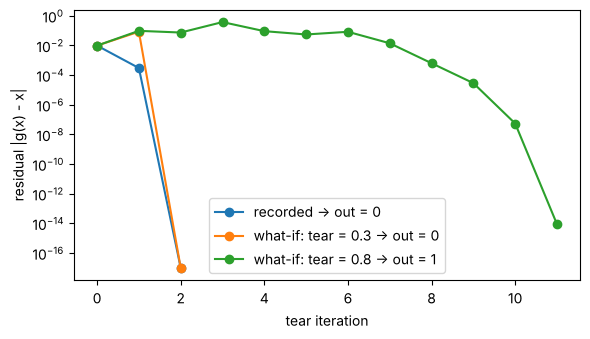

In [11]:
fig, ax = plt.subplots(figsize=(6, 3.5))
for label, trace_ in [("recorded", base), ("what-if: tear = 0.3", results[0.3][0]),
                      ("what-if: tear = 0.8", results[0.8][0])]:
    residuals = [f["residual"] for f in trace_["frames"] if f["checkpoint"] == "iteration"]
    answer = float(state_at(trace_, len(trace_["frames"]) - 1)["out"]["F_A"])
    ax.semilogy(range(len(residuals)), [max(r, 1e-17) for r in residuals], "o-",
                label=f"{label} -> out = {answer:.3g}")
ax.set_xlabel("tear iteration")
ax.set_ylabel("residual |g(x) - x|")
ax.legend()
fig.tight_layout()

Both what-ifs converge. Setting the tear to 0.3 lands back on the recorded answer (`same_answer`
is true), while 0.8 lands on the other steady state, and `compare` names the stream that differs.
A converged solve is not necessarily *the* answer.

The accelerator matters here too. Anderson acceleration (difflow's default) treats the loop as a
root-finding problem for $g(x) - x = 0$, and a root finder is happy to land on an **unstable**
steady state that plain substitution would run away from:

In [12]:
anderson = {"use_initialization": False, "acceleration": "anderson"}
base_a = debug.record(bistable(), anderson)
k_a = summarize(base_a)["iterations"][0]["frame"]
replay_a = debug.record(bistable(), anderson, baseline=base_a["frames"],
                        edits=[{"frame": k_a, "stream": "tear", "field": "F_A", "value": 0.4}])
print("Anderson from 0.4 converged:", replay_a["result"]["converged"],
      "| answer:", float(state_at(replay_a, len(replay_a["frames"]) - 1)["out"]["F_A"]))

Anderson from 0.4 converged: True | answer: 0.5000000002917983


It converged, to $x = 0.5$, the unstable middle state, which a real plant could not sit at. A
what-if is a quick way to find out whether a loop has more than one answer, and which one a
given starting point and solver reach.

## 6. Driving it from a program

`DebugRunner` runs the solve on a worker thread and hands back one event per call, which is the
shape a server or an agent needs. The events are the same JSON objects that
`difflow debug plant.py --json` writes, one per line, after a `hello` that lists every checkpoint,
event, metric, command and capability.

In [13]:
from difflow.debug.jsonproto import hello
from difflow.debug.runner import DebugRunner

runner = DebugRunner(isomerization_loop(), {"acceleration": "wegstein"})
print(runner.start()["checkpoint"])
print(runner.command("break if residual<1e-4")["output"])
event = runner.command("continue")["next"]
print({k: event[k] for k in ("checkpoint", "iteration", "residual", "reason")})
print(runner.command("p recycle.F_n_hexane")["output"])
runner.close()

h = hello()
print("\nprotocol:", h["protocol"])
print("checkpoints:", h["checkpoints"])
print("events:", list(h["events"]))

solve_start
['conditional breakpoint: residual<1e-4']
{'checkpoint': 'iteration', 'iteration': 4, 'residual': 2.239241769785849e-07, 'reason': 'condition: residual<1e-4'}
['recycle.F_n_hexane = 2.66667']

protocol: difflow-dbg/1
checkpoints: ['solve_start', 'before_unit', 'after_unit', 'unit_error', 'iteration', 'after_accel', 'terminated']
events: ['nonfinite', 'inner_unconverged', 'residual_rise', 'unit_error']


An agent connected through `difflow mcp` gets the same debugger as tools: `debug_start`,
`debug_command`, `debug_wait`, `debug_record`, `debug_whatif` and the rest (see
[agents](../docs/agents.md)).

## Summary

| To | Use |
|---|---|
| Step a solve at a terminal | `difflow debug plant.py` |
| ... from a script or notebook | `with debug.attach(): fs.solve()` |
| Find where a NaN is born | `difflow debug plant.py --on-error`, `debug.attach(on_error=True)` |
| Stop before a unit, at an iteration, on a condition or an event | `break UNIT`, `break N`, `break if ...`, `break on ...` |
| See what the residual is made of | `p tear`, `p history`, `diagnose` |
| Try a different next guess | `set tear STREAM.FIELD VALUE` |
| Keep a solve frame by frame | `debug.record`, `summarize`, `state_at` |
| Ask whether another start reaches the same answer | a what-if: `record(..., edits=, baseline=)` and `compare` |
| Drive it from a program | `DebugRunner`, `difflow debug --json`, the `difflow mcp` debug tools |

What it can step: the eager tear iteration (`acceleration="anderson"`, the default, or
`"wegstein"`). `acceleration="none"` iterates inside optimistix, and nothing fires under
`jax.grad` or `jit`. The full reference is [the debugger documentation](../docs/debugger.md).